# XGBoost Intensity (MMI) Classifier — Verification Baseline

Verification tests for the baseline model: calibration, physical plausibility, residuals, monotonicity.

> **Data:** the input CSV is not included in this repository. Place it in Google Drive (or locally) and edit the path in the data-loading cell.

Mounted at /content/drive
  MODEL PREDICTION VERIFICATION

[SETUP]  Training models ...
  Models trained.  Test set: 16,000 rows

[TEST 1]  Calibration analysis ...


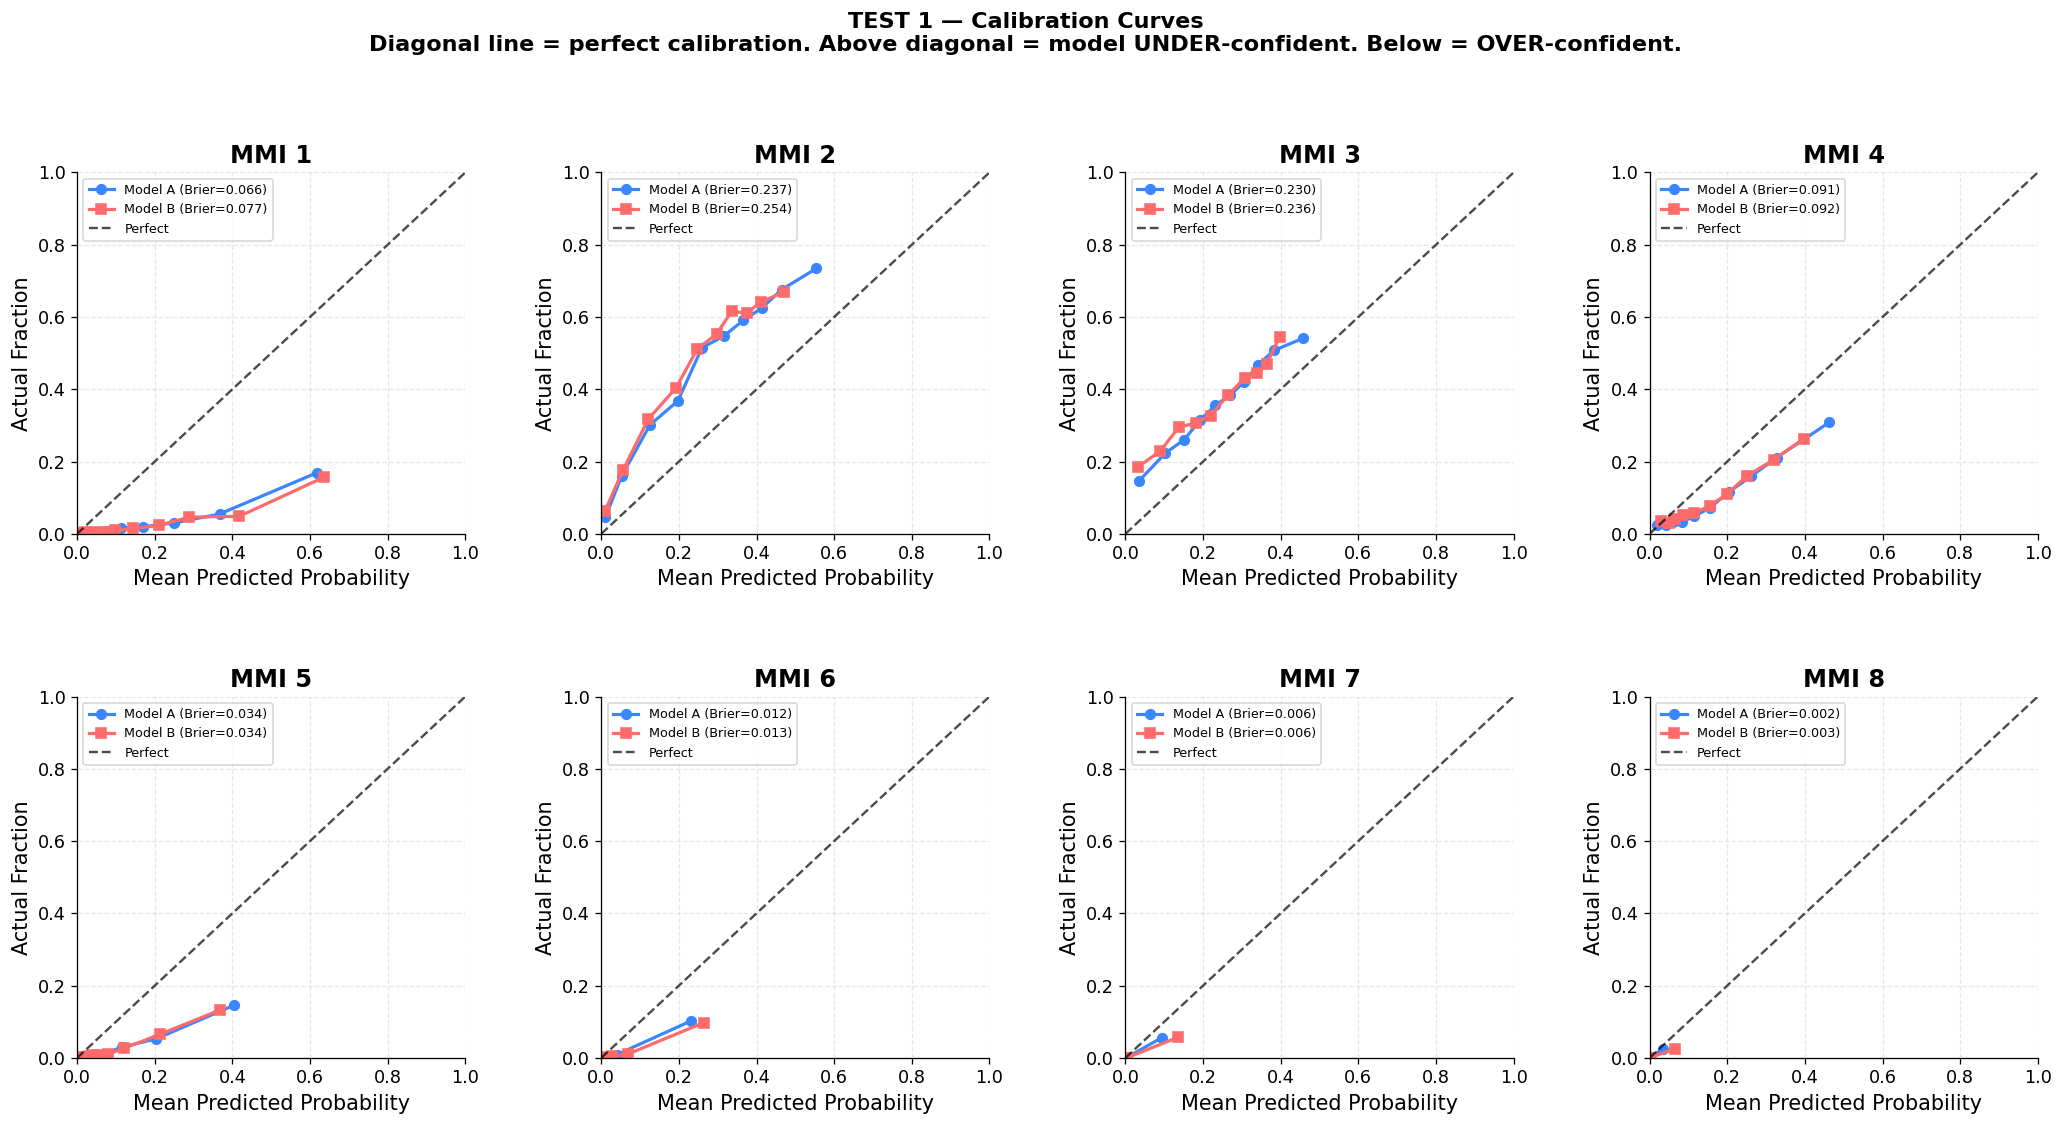


  CALIBRATION RESULTS (Brier Score — lower is better, 0=perfect):
  Model A avg Brier: 0.0848
  Model B avg Brier: 0.0896

  HOW TO READ:
  - Points ON the diagonal = perfectly calibrated
  - Points ABOVE diagonal = model is UNDER-confident (true rate > predicted)
  - Points BELOW diagonal = model is OVER-confident (true rate < predicted)
  - Common MMI classes (2,3) tend to be better calibrated than rare ones (7,8)

[TEST 2]  Physical plausibility — Scenario features ...
  T2a Magnitude → E[MMI] increasing: Model A=NO  Model B=NO
  T2b Distance → E[MMI] decreasing: NO  Spearman r=-0.977
  T2c VS30 → E[MMI] decreasing:     NO  Spearman r=0.078
  T2d Residual correlation with magnitude: r=0.178  (BIAS DETECTED)
  T2e Residual correlation with distance:  r=-0.175  (BIAS DETECTED)
  T2f Residual correlation with VS30:      r=0.009  (acceptable)


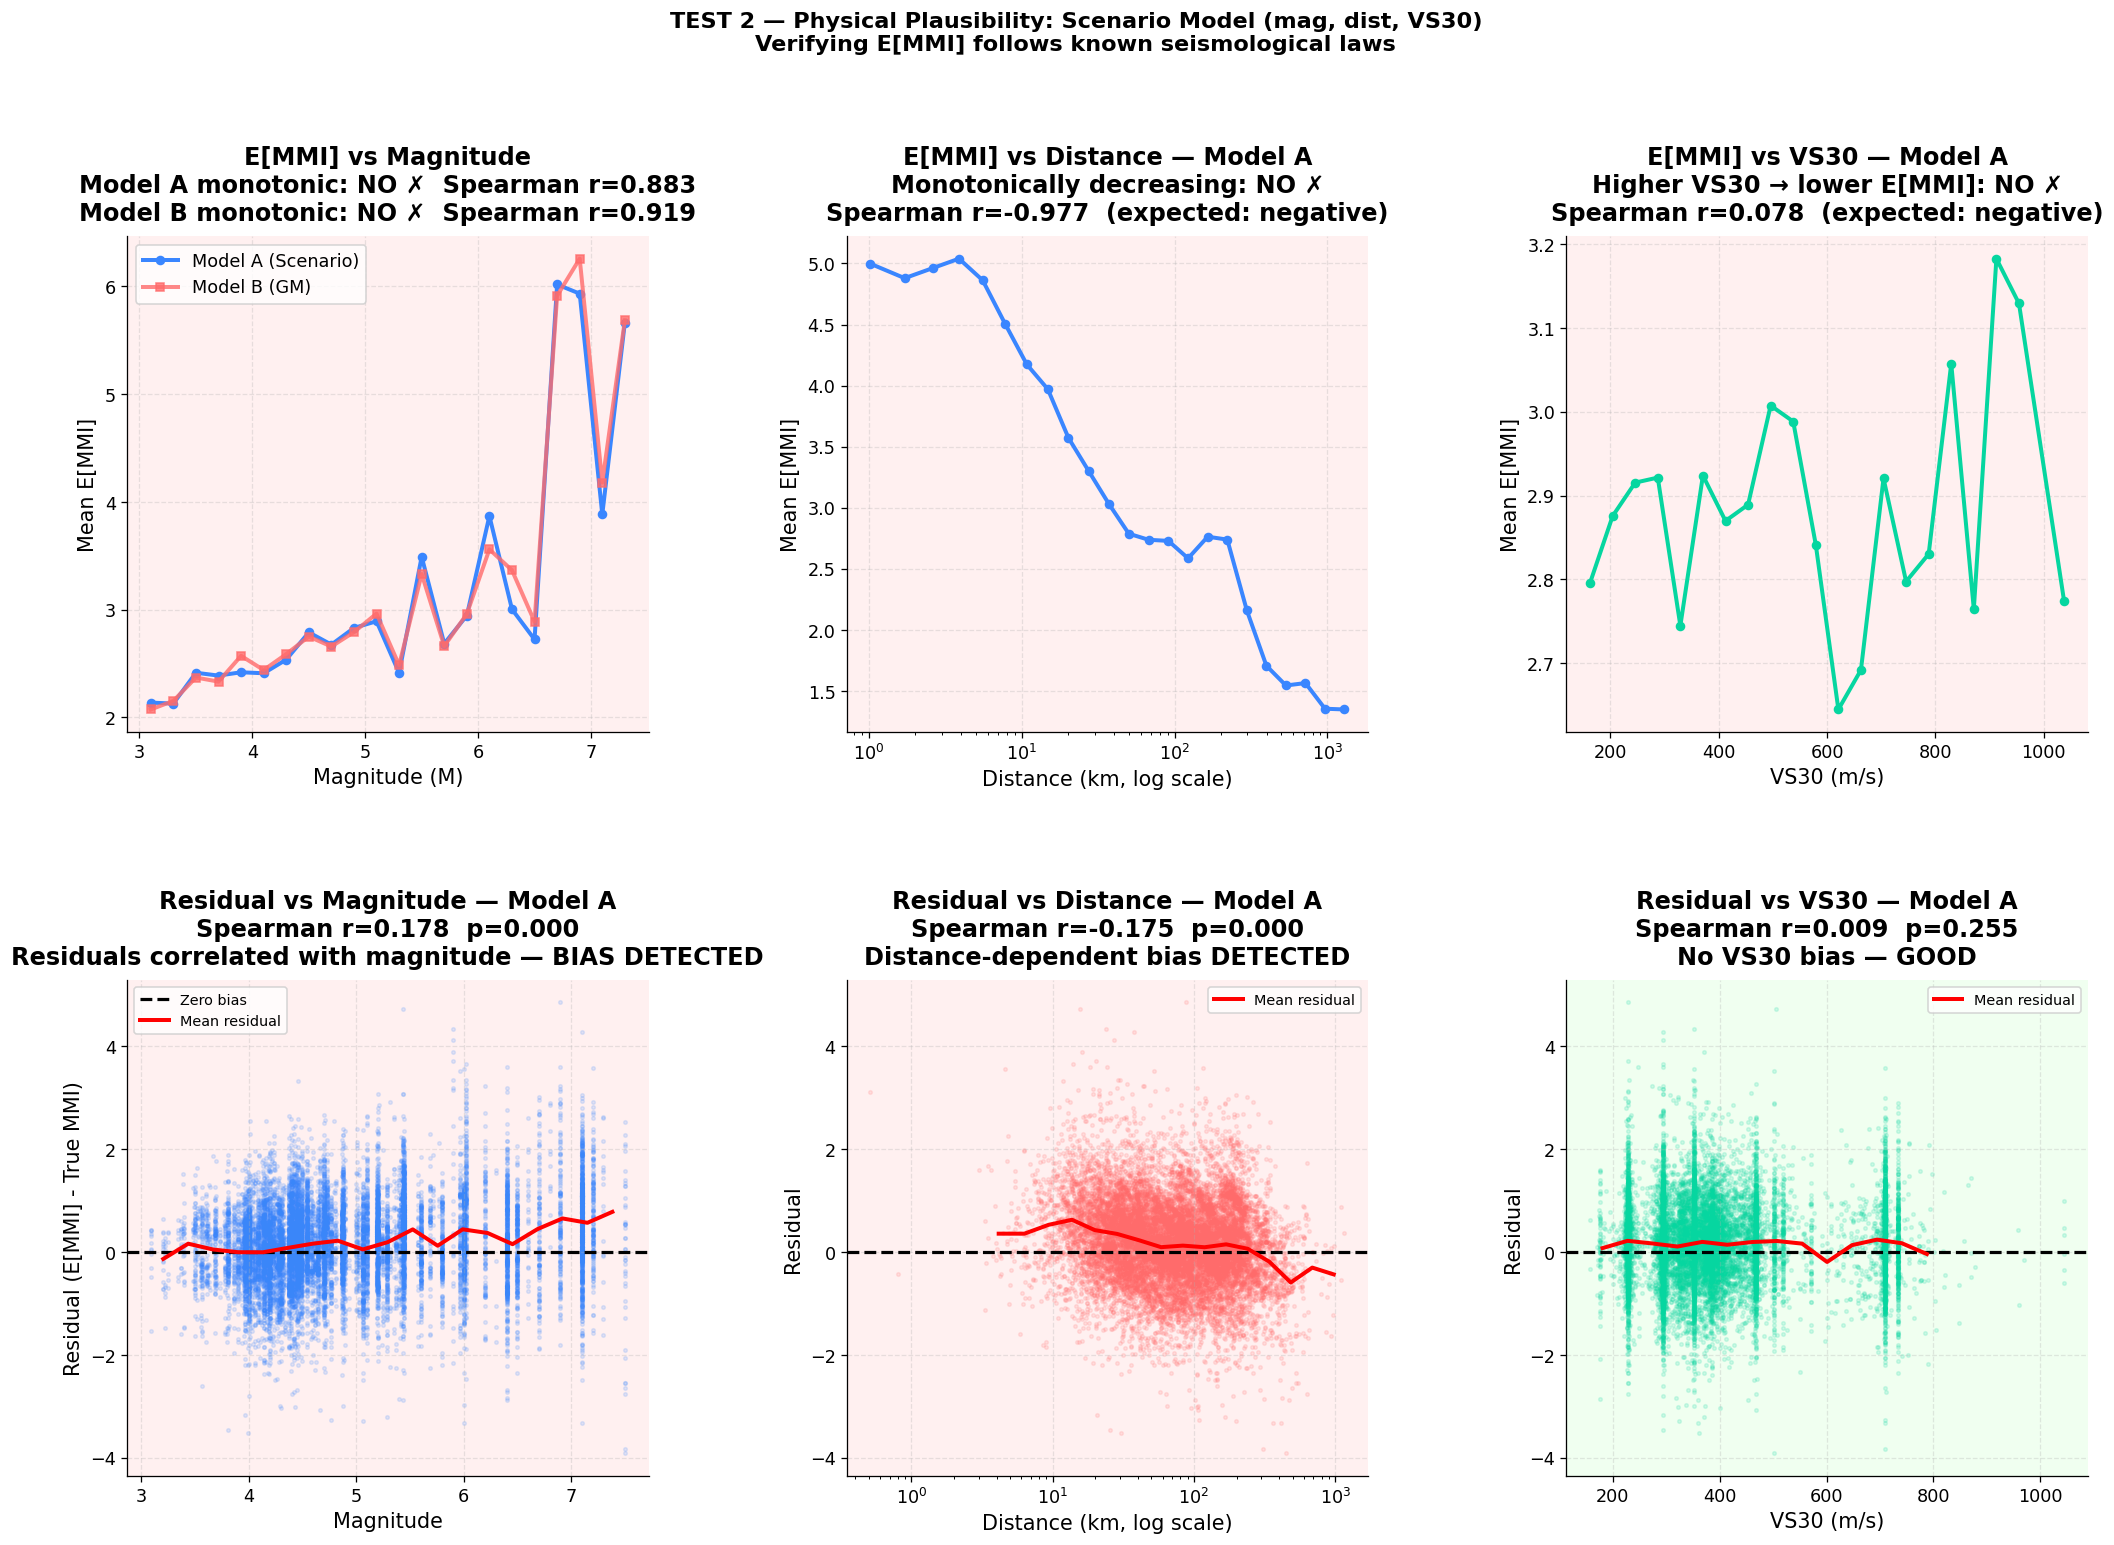


[TEST 3]  Physical plausibility — Ground motion features ...
  T3a PGA → E[MMI] increasing: NO  Spearman r=0.922
  T3b PGV → E[MMI] increasing: NO  Spearman r=0.955
  T3b PGV stronger than PGA: YES ✓
  T3c Residual vs PGA:  r=0.514  (bias detected)
  T3d Residual vs PGV:  r=0.510  (bias detected)


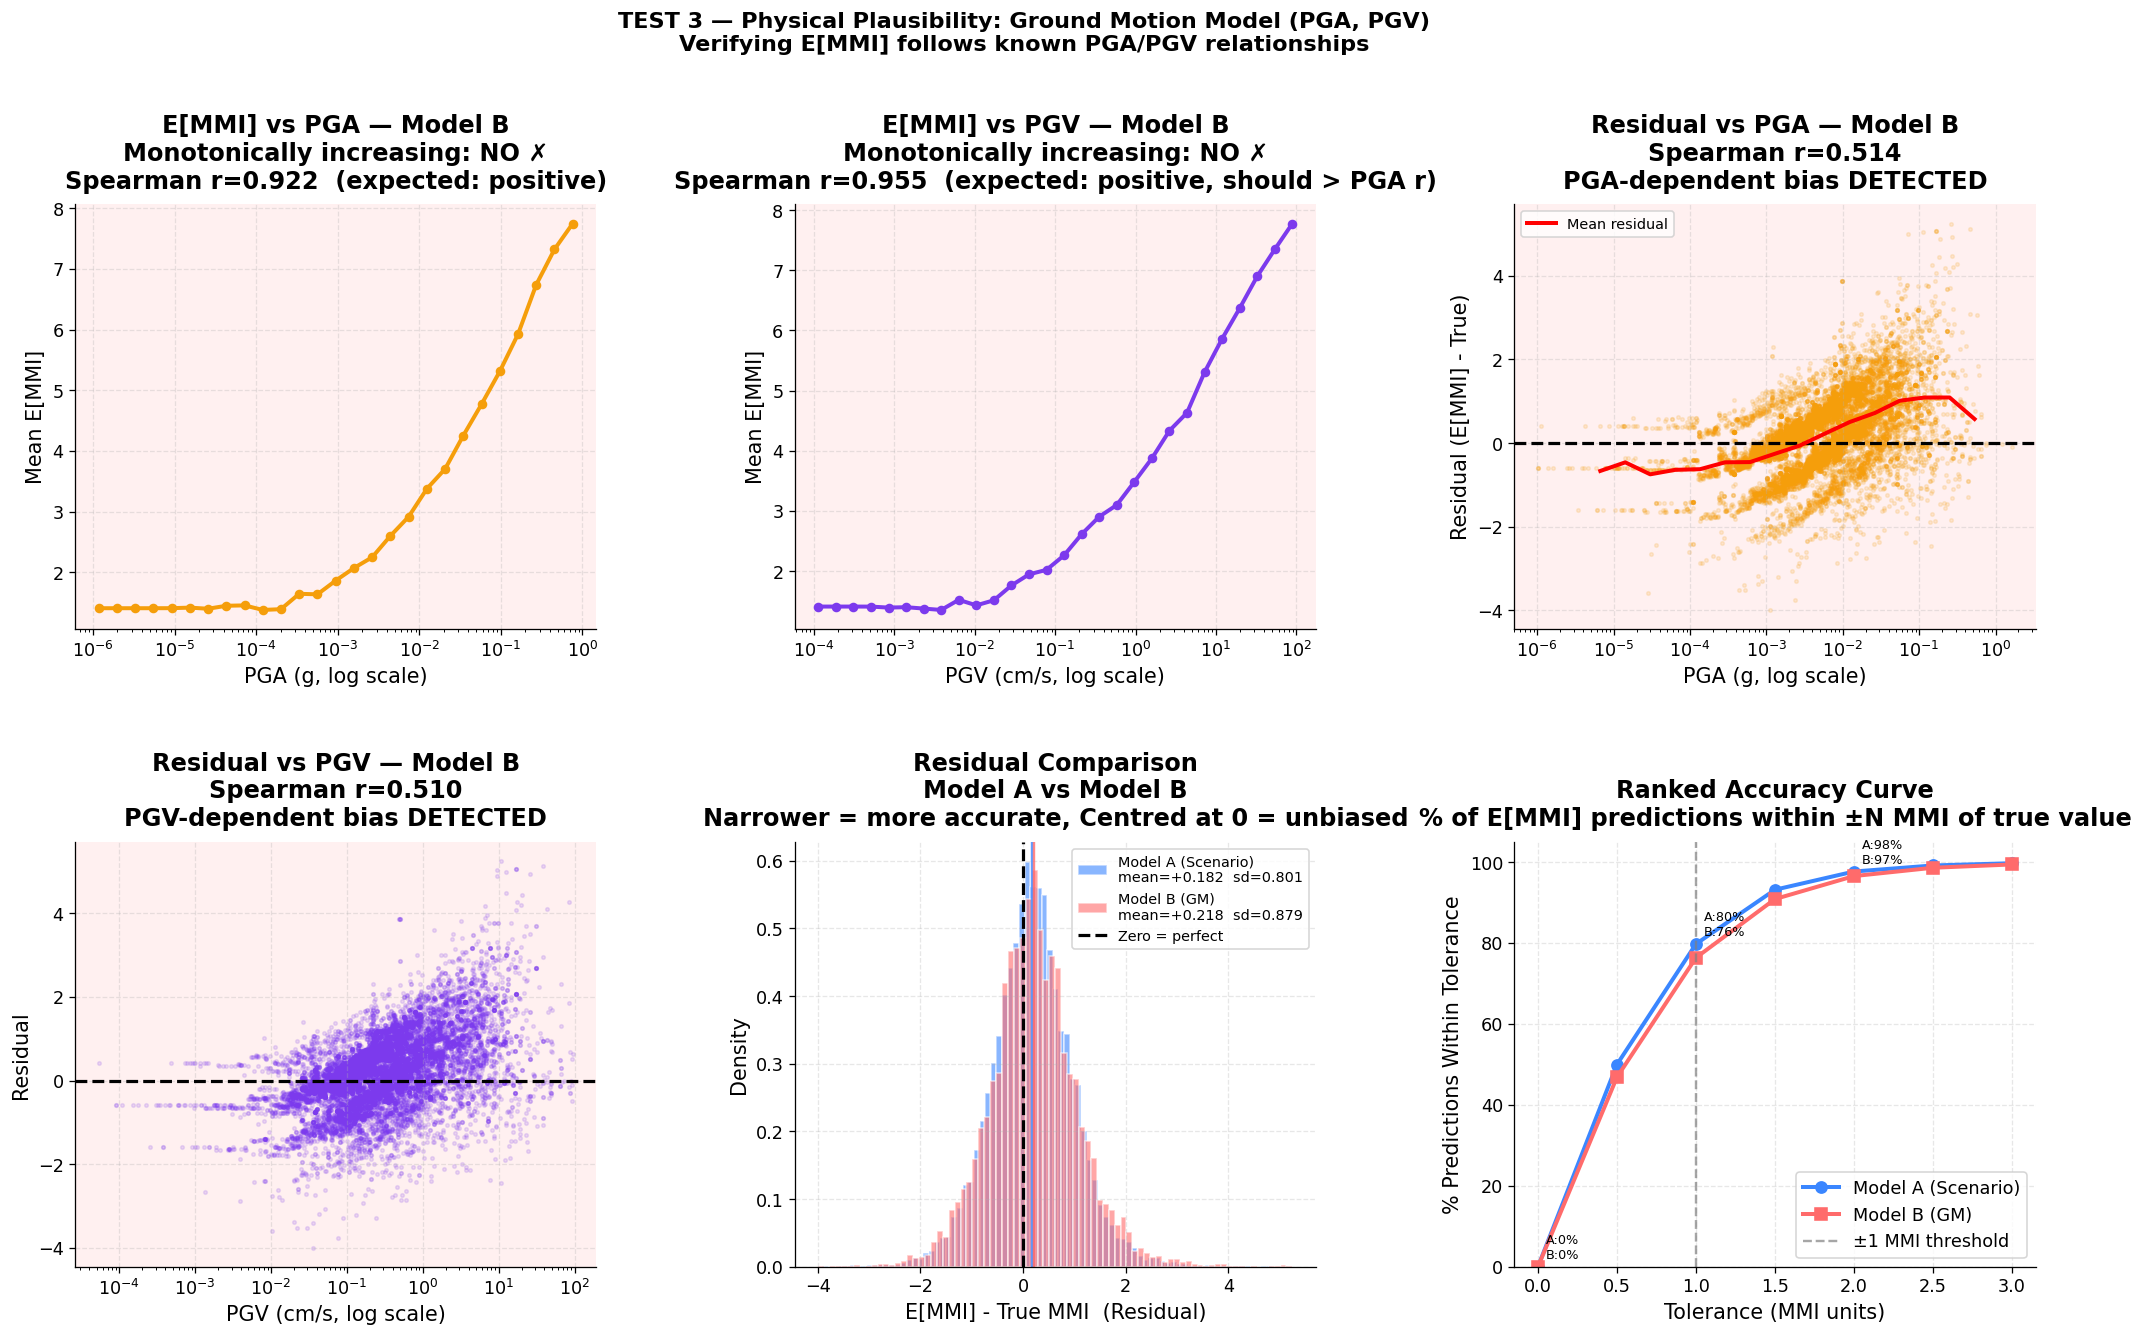


  RANKED ACCURACY:
  Tolerance        Model A (%)  Model B (%)
  ----------------------------------------
  ±0.0 MMI                  0.0%         0.0%
  ±0.5 MMI                 50.0%        46.8%
  ±1.0 MMI                 79.8%        76.4%
  ±1.5 MMI                 93.2%        90.8%
  ±2.0 MMI                 97.7%        96.5%
  ±2.5 MMI                 99.2%        98.6%
  ±3.0 MMI                 99.7%        99.4%

[TEST 4]  Monotonicity stress test (synthetic data) ...
  T4a Magnitude monotonicity violations: 42  FAIL
  T4b Distance monotonicity violations:  35  FAIL
  T4c VS30 monotonicity violations:       27  small violations — tree boundaries
  T4d PGA monotonicity violations:        55  FAIL
  T4e PGV monotonicity violations:        64  FAIL
  T4f Near-field always > far-field: PASS


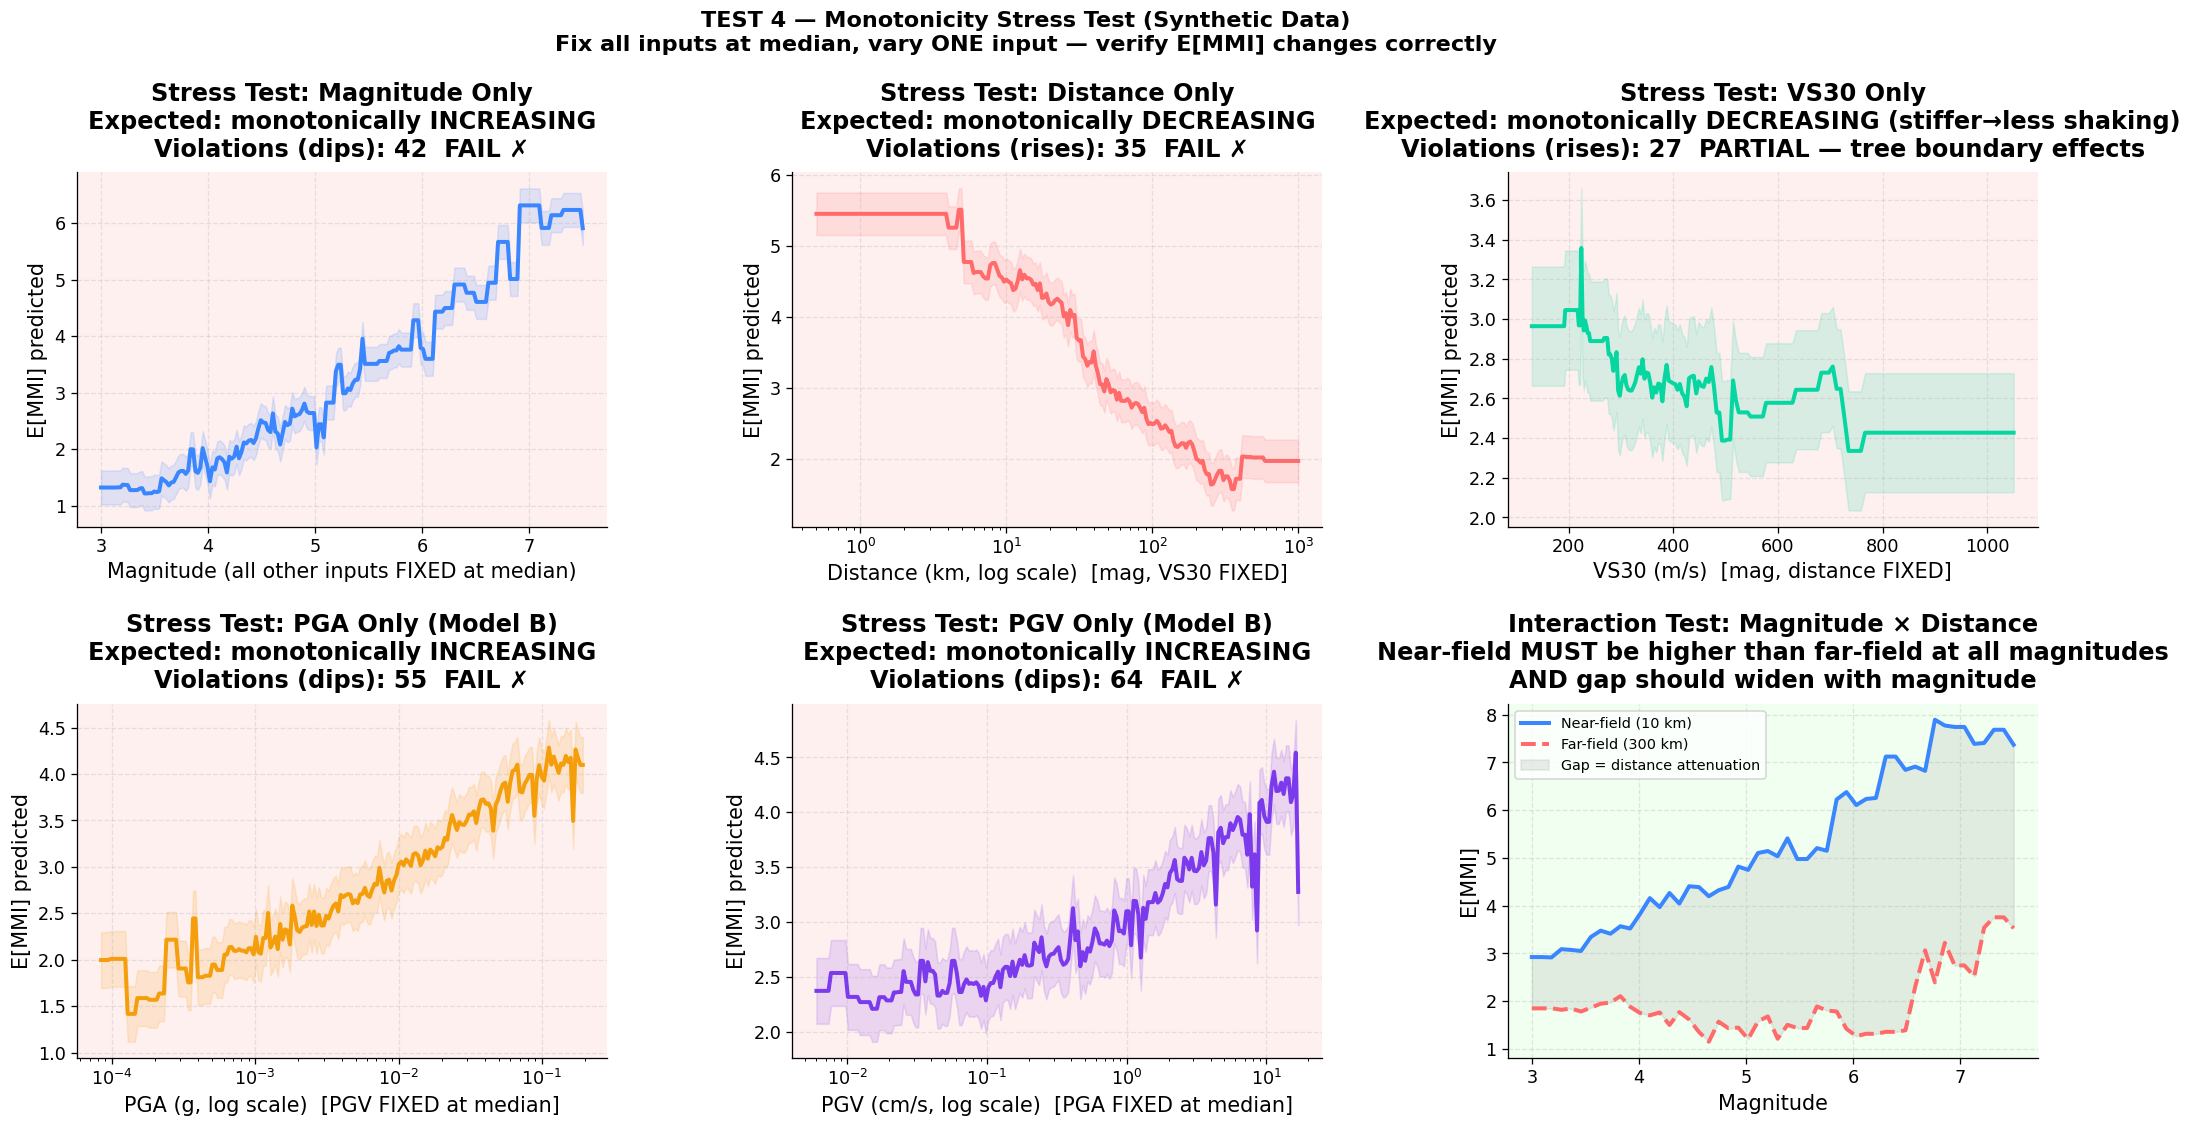


[TEST 5]  Benchmark vs Worden (2012) GMPE ...

  BENCHMARK vs WORDEN (2012) GMPE:
  Method                        RMSE     Bias     Corr
  --------------------------------------------------
  Worden (2012) GMPE          1.3485  -0.7538   0.6193
  XGBoost Model B (GM)        0.9058  +0.2182   0.6463

  XGBoost vs GMPE: RMSE BETTER by 0.4427 MMI units


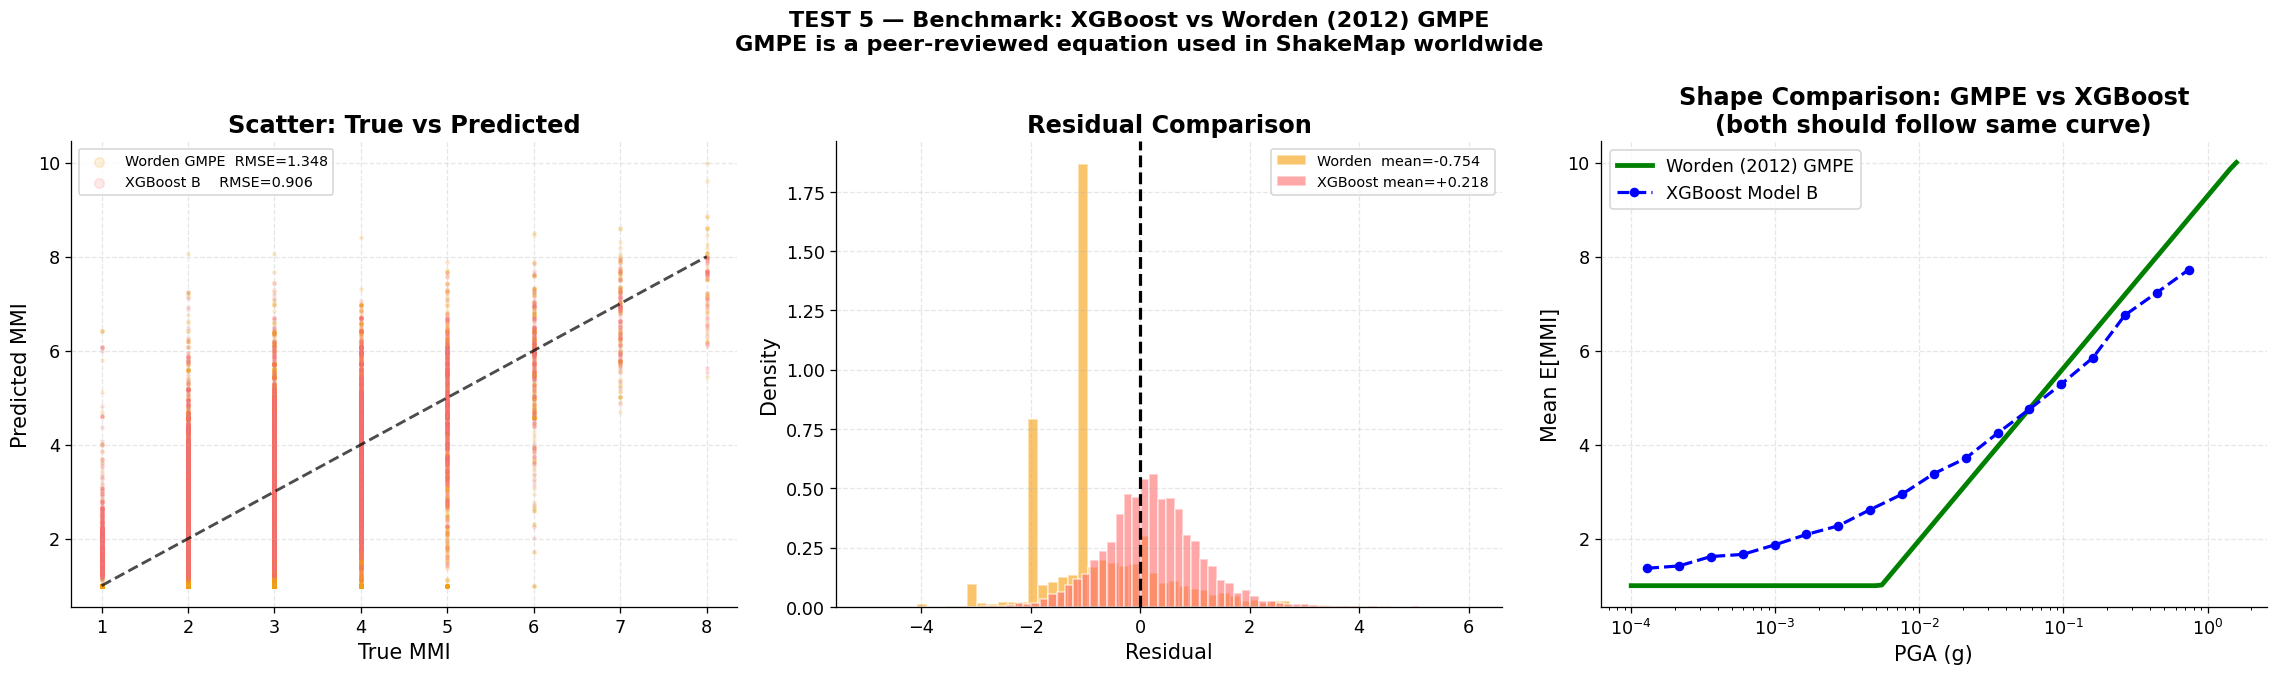


  FINAL VERIFICATION SCORECARD

  SCENARIO MODEL (Model A: mag, dist, VS30)
  ------------------------------------------------------------
  [FAIL ✗]  T2a E[MMI] increases with magnitude         value=0.883  expected=>0.9
  [FAIL ✗]  T2b E[MMI] decreases with distance          value=-0.977  expected=<-0.8
  [FAIL ✗]  T2c E[MMI] decreases with VS30              value=0.078  expected=<0
  [FAIL ✗]  T2d Residuals unbiased vs magnitude         value=0.178  expected=~0
  [FAIL ✗]  T2e Residuals unbiased vs distance          value=-0.175  expected=~0
  [PASS ✓]  T2f Residuals unbiased vs VS30              value=0.009  expected=~0
  [FAIL ✗]  T4a Magnitude monotonicity (synth)          value=42  expected=0 violations
  [FAIL ✗]  T4b Distance monotonicity (synth)           value=35  expected=0 violations
  [FAIL ✗]  T4c VS30 monotonicity (synth)               value=27  expected=≤3 violations
  [PASS ✓]  T4f Near > far at all magnitudes            value=  expected=always

  GROUND MOTION MODEL

In [ ]:
"""
=============================================================================
MODEL PREDICTION VERIFICATION
=============================================================================
QUESTION: "How do we know the model made correct predictions?"

ANSWER: We verify predictions using 7 complementary tests:

  TEST 1  Calibration Curves
          Are predicted probabilities trustworthy?
          If the model says "60% chance of MMI 3", does MMI 3 actually
          occur 60% of the time?

  TEST 2  Physical Plausibility (Scenario Model)
          Does E[MMI] follow known seismological laws?
            - Bigger magnitude  → higher MMI  (must be monotonic)
            - Greater distance  → lower MMI   (must attenuate)
            - Softer soil VS30  → higher MMI  (must amplify)

  TEST 3  Physical Plausibility (Ground Motion Model)
          Does E[MMI] follow known PGA/PGV relationships?
            - Higher PGA → higher MMI (monotonic)
            - Higher PGV → higher MMI (even stronger link)

  TEST 4  Residual Analysis
          Are errors (E[MMI] - true MMI) random and unbiased?
          Systematic patterns reveal what the model gets wrong.

  TEST 5  Probability Sharpness
          A good model is both correct AND confident.
          Uncertain models give flat distributions (near 1/8 ≈ 12.5% each).

  TEST 6  Monotonicity Tests (Stress Testing)
          Create synthetic data and check the model's logic:
            - If we increase magnitude only, does E[MMI] always go up?
            - If we increase distance only, does E[MMI] always go down?

  TEST 7  Benchmark vs Known GMPE
          Compare E[MMI] against the Worden (2012) GMPE formula —
          a peer-reviewed equation published in the seismology literature.
=============================================================================
"""

# !pip install xgboost scikit-learn matplotlib seaborn pandas numpy -q

%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy.stats import spearmanr, pearsonr

from google.colab import drive
drive.mount("/content/drive")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    mean_absolute_error, brier_score_loss,
    confusion_matrix, classification_report,
)
from xgboost import XGBClassifier

# ── Style ─────────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 13,
    "axes.titlesize": 15, "axes.labelsize": 13,
    "xtick.labelsize": 11, "ytick.labelsize": 11,
    "legend.fontsize": 11, "figure.dpi": 115,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "grid.linestyle": "--",
})
CMAP = "plasma"; C_A = "#3A86FF"; C_B = "#FF6B6B"; C_T = "#06D6A0"; C_G = "#F59E0B"

# ─────────────────────────────────────────────────────────────────
# STEP 1 — TRAIN MODELS  (same setup as main program)
# ─────────────────────────────────────────────────────────────────
print("=" * 65)
print("  MODEL PREDICTION VERIFICATION")
print("=" * 65)
print("\n[SETUP]  Training models ...")

CSV_PATH = "/content/drive/MyDrive/Colab Notebooks/data/intensityfiles_alldata_March112026.csv"
EXACT_COLS = {
    "magnitude": "mag", "RRUP_Combined": "dist",
    "VS30 (Thompson (2020) geology based Proxies)": "vs30",
    "PGA (g)": "pga", "PGV": "pgv", "intensity": "intensity",
}
df = pd.read_csv(CSV_PATH, usecols=list(EXACT_COLS.keys())).rename(columns=EXACT_COLS)
df = df[(df["pga"] > 0) & (df["pgv"] > 0)].dropna().reset_index(drop=True)
df["mmi_class"] = df["intensity"].astype(int).clip(1, 8)
df["log_dist"]  = np.log1p(df["dist"])
df["log_pga"]   = np.log(df["pga"])
df["log_pgv"]   = np.log(df["pgv"])
df["log_vs30"]  = np.log(df["vs30"])

le      = LabelEncoder()
df["label"] = le.fit_transform(df["mmi_class"])
classes = le.classes_; n_cls = len(classes); mmi_vals = classes.astype(float)

FEAT_SC = ["mag", "log_dist", "log_vs30"]
FEAT_GM = ["log_pga", "log_pgv"]

df_s = df.sample(n=80_000, random_state=42)
X_sc = df_s[FEAT_SC].to_numpy(); X_gm = df_s[FEAT_GM].to_numpy()
y    = df_s["label"].to_numpy()

X_sc_tr, X_sc_te, X_gm_tr, X_gm_te, y_tr, y_te = train_test_split(
    X_sc, X_gm, y, test_size=0.2, stratify=y, random_state=42)

counts  = np.bincount(y_tr, minlength=n_cls)
weights = counts.sum() / (n_cls * counts + 1e-9)
sw_tr   = np.array([weights[yi] for yi in y_tr])

XGB_PARAMS = dict(objective="multi:softprob", num_class=n_cls,
    n_estimators=500, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
    gamma=0.1, reg_alpha=0.1, reg_lambda=1.0,
    eval_metric="mlogloss", random_state=42, n_jobs=-1,
    tree_method="hist", early_stopping_rounds=30)

xgb_sc = XGBClassifier(**XGB_PARAMS)
xgb_gm = XGBClassifier(**XGB_PARAMS)
xgb_sc.fit(X_sc_tr, y_tr, sample_weight=sw_tr,
           eval_set=[(X_sc_te, y_te)], verbose=False)
xgb_gm.fit(X_gm_tr, y_tr, sample_weight=sw_tr,
           eval_set=[(X_gm_te, y_te)], verbose=False)

# Predictions
y_pred_sc  = xgb_sc.predict(X_sc_te)
y_proba_sc = xgb_sc.predict_proba(X_sc_te)
y_pred_gm  = xgb_gm.predict(X_gm_te)
y_proba_gm = xgb_gm.predict_proba(X_gm_te)

def expected_mmi(proba):
    return (proba * mmi_vals).sum(axis=1)

E_sc     = expected_mmi(y_proba_sc)
E_gm     = expected_mmi(y_proba_gm)
true_mmi = le.inverse_transform(y_te).astype(float)
res_sc   = E_sc  - true_mmi
res_gm   = E_gm  - true_mmi

print(f"  Models trained.  Test set: {len(y_te):,} rows")

# Full-data predictions for physical tests
prob_sc_full = xgb_sc.predict_proba(df[FEAT_SC].to_numpy())
prob_gm_full = xgb_gm.predict_proba(df[FEAT_GM].to_numpy())
df["E_sc"]   = expected_mmi(prob_sc_full)
df["E_gm"]   = expected_mmi(prob_gm_full)

# ═══════════════════════════════════════════════════════════════════
# TEST 1 — CALIBRATION CURVES
# "Are predicted probabilities trustworthy?"
# ═══════════════════════════════════════════════════════════════════
print("\n[TEST 1]  Calibration analysis ...")

# For each MMI class: does "model says 40% chance" mean 40% frequency?
fig = plt.figure(figsize=(22, 10))
fig.suptitle(
    "TEST 1 — Calibration Curves\n"
    "Diagonal line = perfect calibration. "
    "Above diagonal = model UNDER-confident. Below = OVER-confident.",
    fontsize=14, fontweight="bold", y=1.02)
gs = gridspec.GridSpec(2, 4, figure=fig, hspace=0.45, wspace=0.35)

brier_sc_list, brier_gm_list = [], []

for idx, cls_idx in enumerate(range(n_cls)):
    ax = fig.add_subplot(gs[idx // 4, idx % 4])
    mmi_val = int(classes[cls_idx])

    # Binary problem: "is this MMI {mmi_val}?" yes=1, no=0
    y_binary = (y_te == cls_idx).astype(int)
    prob_col_sc = y_proba_sc[:, cls_idx]
    prob_col_gm = y_proba_gm[:, cls_idx]

    # calibration_curve bins predicted probabilities and computes actual frequency
    try:
        frac_pos_sc, mean_pred_sc = calibration_curve(
            y_binary, prob_col_sc, n_bins=10, strategy="quantile")
        ax.plot(mean_pred_sc, frac_pos_sc, "o-", color=C_A, lw=2,
                label=f"Model A (Brier={brier_score_loss(y_binary, prob_col_sc):.3f})")
        brier_sc_list.append(brier_score_loss(y_binary, prob_col_sc))
    except Exception:
        pass

    try:
        frac_pos_gm, mean_pred_gm = calibration_curve(
            y_binary, prob_col_gm, n_bins=10, strategy="quantile")
        ax.plot(mean_pred_gm, frac_pos_gm, "s-", color=C_B, lw=2,
                label=f"Model B (Brier={brier_score_loss(y_binary, prob_col_gm):.3f})")
        brier_gm_list.append(brier_score_loss(y_binary, prob_col_gm))
    except Exception:
        pass

    ax.plot([0, 1], [0, 1], "k--", lw=1.5, alpha=0.7, label="Perfect")
    ax.set_xlabel("Mean Predicted Probability")
    ax.set_ylabel("Actual Fraction")
    ax.set_title(f"MMI {mmi_val}", fontweight="bold")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print(f"\n  CALIBRATION RESULTS (Brier Score — lower is better, 0=perfect):")
print(f"  Model A avg Brier: {np.mean(brier_sc_list):.4f}")
print(f"  Model B avg Brier: {np.mean(brier_gm_list):.4f}")
print()
print("  HOW TO READ:")
print("  - Points ON the diagonal = perfectly calibrated")
print("  - Points ABOVE diagonal = model is UNDER-confident (true rate > predicted)")
print("  - Points BELOW diagonal = model is OVER-confident (true rate < predicted)")
print("  - Common MMI classes (2,3) tend to be better calibrated than rare ones (7,8)")

# ═══════════════════════════════════════════════════════════════════
# TEST 2 — PHYSICAL PLAUSIBILITY: SCENARIO FEATURES
# "Does the model respect known seismological laws?"
# ═══════════════════════════════════════════════════════════════════
print("\n[TEST 2]  Physical plausibility — Scenario features ...")

fig = plt.figure(figsize=(22, 14))
fig.suptitle(
    "TEST 2 — Physical Plausibility: Scenario Model (mag, dist, VS30)\n"
    "Verifying E[MMI] follows known seismological laws",
    fontsize=14, fontweight="bold", y=1.02)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.50, wspace=0.38)

# ── T2a: E[MMI] vs Magnitude — must be monotonically increasing ──
ax = fig.add_subplot(gs[0, 0])
mag_bins = np.arange(3.0, 7.6, 0.2)
mag_mid  = (mag_bins[:-1] + mag_bins[1:]) / 2
E_by_mag_sc, E_by_mag_gm, n_by_mag = [], [], []
for lo, hi in zip(mag_bins[:-1], mag_bins[1:]):
    m = (df["mag"] >= lo) & (df["mag"] < hi)
    E_by_mag_sc.append(df.loc[m, "E_sc"].mean() if m.sum() > 10 else np.nan)
    E_by_mag_gm.append(df.loc[m, "E_gm"].mean() if m.sum() > 10 else np.nan)
    n_by_mag.append(m.sum())

E_by_mag_sc = np.array(E_by_mag_sc)
E_by_mag_gm = np.array(E_by_mag_gm)
valid = ~np.isnan(E_by_mag_sc)

ax.plot(mag_mid[valid], E_by_mag_sc[valid], "o-", color=C_A, lw=2.5,
        markersize=5, label="Model A (Scenario)")
ax.plot(mag_mid[valid], E_by_mag_gm[valid], "s-", color=C_B, lw=2.5,
        markersize=5, label="Model B (GM)", alpha=0.8)

# Monotonicity check
is_mono_sc = all(np.diff(E_by_mag_sc[valid]) >= -0.05)
is_mono_gm = all(np.diff(E_by_mag_gm[valid]) >= -0.05)
spear_sc, _ = spearmanr(mag_mid[valid], E_by_mag_sc[valid])
spear_gm, _ = spearmanr(mag_mid[valid], E_by_mag_gm[valid])

ax.set_xlabel("Magnitude (M)"); ax.set_ylabel("Mean E[MMI]")
ax.set_title(f"E[MMI] vs Magnitude\n"
             f"Model A monotonic: {'YES ✓' if is_mono_sc else 'NO ✗'}  "
             f"Spearman r={spear_sc:.3f}\n"
             f"Model B monotonic: {'YES ✓' if is_mono_gm else 'NO ✗'}  "
             f"Spearman r={spear_gm:.3f}",
             fontweight="bold", pad=10)
ax.legend()
ax.set_facecolor("#f0fff0" if is_mono_sc else "#fff0f0")
print(f"  T2a Magnitude → E[MMI] increasing: Model A={'YES' if is_mono_sc else 'NO'}  "
      f"Model B={'YES' if is_mono_gm else 'NO'}")

# ── T2b: E[MMI] vs Distance — must be monotonically decreasing ──
ax = fig.add_subplot(gs[0, 1])
dist_log_bins = np.linspace(np.log1p(0.3), np.log1p(1500), 25)
dist_mid_log  = (dist_log_bins[:-1] + dist_log_bins[1:]) / 2
E_by_dist, n_by_dist = [], []
for lo, hi in zip(dist_log_bins[:-1], dist_log_bins[1:]):
    m = (df["log_dist"] >= lo) & (df["log_dist"] < hi)
    E_by_dist.append(df.loc[m, "E_sc"].mean() if m.sum() > 10 else np.nan)
    n_by_dist.append(m.sum())

E_by_dist = np.array(E_by_dist)
valid_d    = ~np.isnan(E_by_dist)
dist_mid_km = np.expm1(dist_mid_log)

ax.plot(dist_mid_km[valid_d], E_by_dist[valid_d], "o-", color=C_A, lw=2.5, markersize=5)
ax.set_xscale("log")

is_decreasing = all(np.diff(E_by_dist[valid_d]) <= 0.05)
spear_dist, _ = spearmanr(dist_mid_km[valid_d], E_by_dist[valid_d])

ax.set_xlabel("Distance (km, log scale)"); ax.set_ylabel("Mean E[MMI]")
ax.set_title(f"E[MMI] vs Distance — Model A\n"
             f"Monotonically decreasing: {'YES ✓' if is_decreasing else 'NO ✗'}\n"
             f"Spearman r={spear_dist:.3f}  (expected: negative)",
             fontweight="bold", pad=10)
ax.set_facecolor("#f0fff0" if is_decreasing else "#fff0f0")
print(f"  T2b Distance → E[MMI] decreasing: {'YES' if is_decreasing else 'NO'}  "
      f"Spearman r={spear_dist:.3f}")

# ── T2c: E[MMI] vs VS30 — should decrease (stiffer rock = less amplification)
ax = fig.add_subplot(gs[0, 2])
vs30_bins = np.linspace(100, 1100, 25)
vs30_mid  = (vs30_bins[:-1] + vs30_bins[1:]) / 2
E_by_vs30 = []
for lo, hi in zip(vs30_bins[:-1], vs30_bins[1:]):
    m = (df["vs30"] >= lo) & (df["vs30"] < hi)
    E_by_vs30.append(df.loc[m, "E_sc"].mean() if m.sum() > 10 else np.nan)

E_by_vs30 = np.array(E_by_vs30)
valid_v    = ~np.isnan(E_by_vs30)
spear_vs30, _ = spearmanr(vs30_mid[valid_v], E_by_vs30[valid_v])
is_vs30_correct = spear_vs30 < 0   # should be negative

ax.plot(vs30_mid[valid_v], E_by_vs30[valid_v], "o-", color=C_T, lw=2.5, markersize=5)
ax.set_xlabel("VS30 (m/s)"); ax.set_ylabel("Mean E[MMI]")
ax.set_title(f"E[MMI] vs VS30 — Model A\n"
             f"Higher VS30 → lower E[MMI]: {'YES ✓' if is_vs30_correct else 'NO ✗'}\n"
             f"Spearman r={spear_vs30:.3f}  (expected: negative)",
             fontweight="bold", pad=10)
ax.set_facecolor("#f0fff0" if is_vs30_correct else "#fff0f0")
print(f"  T2c VS30 → E[MMI] decreasing:     {'YES' if is_vs30_correct else 'NO'}  "
      f"Spearman r={spear_vs30:.3f}")

# ── T2d: Residual vs Magnitude — errors should NOT correlate with features
ax = fig.add_subplot(gs[1, 0])
mag_te  = X_sc_te[:, 0]
spear_res_mag, p_mag = spearmanr(mag_te, res_sc)
ax.scatter(mag_te, res_sc, alpha=0.15, s=5, c=C_A)
ax.axhline(0, color="k", ls="--", lw=2, label="Zero bias")

# Trend line
mag_bins2 = np.linspace(mag_te.min(), mag_te.max(), 20)
res_by_mag = [res_sc[(mag_te>=l)&(mag_te<h)].mean()
              for l, h in zip(mag_bins2[:-1], mag_bins2[1:])
              if ((mag_te>=l)&(mag_te<h)).sum() > 10]
mag_mid2   = [(l+h)/2 for l, h in zip(mag_bins2[:-1], mag_bins2[1:])
              if ((mag_te>=l)&(mag_te<h)).sum() > 10]
ax.plot(mag_mid2, res_by_mag, "r-", lw=2.5, label="Mean residual")

ax.set_xlabel("Magnitude"); ax.set_ylabel("Residual (E[MMI] - True MMI)")
ax.set_title(f"Residual vs Magnitude — Model A\n"
             f"Spearman r={spear_res_mag:.3f}  p={p_mag:.3f}\n"
             f"{'Residuals correlated with magnitude — BIAS DETECTED' if abs(spear_res_mag)>0.1 else 'Residuals uncorrelated — GOOD'}",
             fontweight="bold", pad=10)
ax.legend(fontsize=9)
ax.set_facecolor("#f0fff0" if abs(spear_res_mag) < 0.15 else "#fff0f0")
print(f"  T2d Residual correlation with magnitude: r={spear_res_mag:.3f}  "
      f"({'BIAS DETECTED' if abs(spear_res_mag)>0.15 else 'acceptable'})")

# ── T2e: Residual vs Distance
ax = fig.add_subplot(gs[1, 1])
dist_te = np.expm1(X_sc_te[:, 1])
spear_res_dist, p_dist = spearmanr(dist_te, res_sc)
ax.scatter(dist_te, res_sc, alpha=0.15, s=5, c=C_B)
ax.axhline(0, color="k", ls="--", lw=2)
ax.set_xscale("log")

dist_log_te = X_sc_te[:, 1]
dist_bins3 = np.linspace(dist_log_te.min(), dist_log_te.max(), 20)
res_by_dist = [res_sc[(dist_log_te>=l)&(dist_log_te<h)].mean()
               for l, h in zip(dist_bins3[:-1], dist_bins3[1:])
               if ((dist_log_te>=l)&(dist_log_te<h)).sum() > 10]
dist_mid3 = [np.expm1((l+h)/2) for l, h in zip(dist_bins3[:-1], dist_bins3[1:])
             if ((dist_log_te>=l)&(dist_log_te<h)).sum() > 10]
ax.plot(dist_mid3, res_by_dist, "r-", lw=2.5, label="Mean residual")

ax.set_xlabel("Distance (km, log scale)"); ax.set_ylabel("Residual")
ax.set_title(f"Residual vs Distance — Model A\n"
             f"Spearman r={spear_res_dist:.3f}  p={p_dist:.3f}\n"
             f"{'Distance-dependent bias DETECTED' if abs(spear_res_dist)>0.1 else 'No distance bias — GOOD'}",
             fontweight="bold", pad=10)
ax.legend(fontsize=9)
ax.set_facecolor("#f0fff0" if abs(spear_res_dist) < 0.15 else "#fff0f0")
print(f"  T2e Residual correlation with distance:  r={spear_res_dist:.3f}  "
      f"({'BIAS DETECTED' if abs(spear_res_dist)>0.15 else 'acceptable'})")

# ── T2f: Residual vs VS30
ax = fig.add_subplot(gs[1, 2])
vs30_te = np.exp(X_sc_te[:, 2])
spear_res_vs30, p_vs30 = spearmanr(vs30_te, res_sc)
ax.scatter(vs30_te, res_sc, alpha=0.15, s=5, c=C_T)
ax.axhline(0, color="k", ls="--", lw=2)

vs30_bins4 = np.linspace(vs30_te.min(), vs30_te.max(), 20)
res_by_vs30_te = [res_sc[(vs30_te>=l)&(vs30_te<h)].mean()
                  for l, h in zip(vs30_bins4[:-1], vs30_bins4[1:])
                  if ((vs30_te>=l)&(vs30_te<h)).sum() > 10]
vs30_mid4 = [(l+h)/2 for l, h in zip(vs30_bins4[:-1], vs30_bins4[1:])
             if ((vs30_te>=l)&(vs30_te<h)).sum() > 10]
ax.plot(vs30_mid4, res_by_vs30_te, "r-", lw=2.5, label="Mean residual")

ax.set_xlabel("VS30 (m/s)"); ax.set_ylabel("Residual")
ax.set_title(f"Residual vs VS30 — Model A\n"
             f"Spearman r={spear_res_vs30:.3f}  p={p_vs30:.3f}\n"
             f"{'VS30-dependent bias DETECTED' if abs(spear_res_vs30)>0.1 else 'No VS30 bias — GOOD'}",
             fontweight="bold", pad=10)
ax.legend(fontsize=9)
ax.set_facecolor("#f0fff0" if abs(spear_res_vs30) < 0.15 else "#fff0f0")
print(f"  T2f Residual correlation with VS30:      r={spear_res_vs30:.3f}  "
      f"({'BIAS DETECTED' if abs(spear_res_vs30)>0.15 else 'acceptable'})")

plt.tight_layout(); plt.show()

# ═══════════════════════════════════════════════════════════════════
# TEST 3 — PHYSICAL PLAUSIBILITY: GROUND MOTION FEATURES
# ═══════════════════════════════════════════════════════════════════
print("\n[TEST 3]  Physical plausibility — Ground motion features ...")

fig = plt.figure(figsize=(22, 12))
fig.suptitle(
    "TEST 3 — Physical Plausibility: Ground Motion Model (PGA, PGV)\n"
    "Verifying E[MMI] follows known PGA/PGV relationships",
    fontsize=14, fontweight="bold", y=1.02)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.50, wspace=0.38)

# ── T3a: E[MMI] vs log(PGA) — must be increasing
ax = fig.add_subplot(gs[0, 0])
pga_log_bins = np.linspace(df["log_pga"].min(), df["log_pga"].max(), 30)
pga_mid      = (pga_log_bins[:-1] + pga_log_bins[1:]) / 2
E_by_pga     = []
for lo, hi in zip(pga_log_bins[:-1], pga_log_bins[1:]):
    m = (df["log_pga"] >= lo) & (df["log_pga"] < hi)
    E_by_pga.append(df.loc[m, "E_gm"].mean() if m.sum() > 10 else np.nan)

E_by_pga  = np.array(E_by_pga)
valid_p   = ~np.isnan(E_by_pga)
spear_pga, _ = spearmanr(pga_mid[valid_p], E_by_pga[valid_p])
is_pga_mono  = all(np.diff(E_by_pga[valid_p]) >= -0.05)

ax.plot(np.exp(pga_mid[valid_p]), E_by_pga[valid_p], "o-",
        color=C_G, lw=2.5, markersize=5)
ax.set_xscale("log")
ax.set_xlabel("PGA (g, log scale)"); ax.set_ylabel("Mean E[MMI]")
ax.set_title(f"E[MMI] vs PGA — Model B\n"
             f"Monotonically increasing: {'YES ✓' if is_pga_mono else 'NO ✗'}\n"
             f"Spearman r={spear_pga:.3f}  (expected: positive)",
             fontweight="bold", pad=10)
ax.set_facecolor("#f0fff0" if is_pga_mono else "#fff0f0")
print(f"  T3a PGA → E[MMI] increasing: {'YES' if is_pga_mono else 'NO'}  "
      f"Spearman r={spear_pga:.3f}")

# ── T3b: E[MMI] vs log(PGV) — must be increasing (stronger link than PGA)
ax = fig.add_subplot(gs[0, 1])
pgv_log_bins = np.linspace(df["log_pgv"].min(), df["log_pgv"].max(), 30)
pgv_mid      = (pgv_log_bins[:-1] + pgv_log_bins[1:]) / 2
E_by_pgv     = []
for lo, hi in zip(pgv_log_bins[:-1], pgv_log_bins[1:]):
    m = (df["log_pgv"] >= lo) & (df["log_pgv"] < hi)
    E_by_pgv.append(df.loc[m, "E_gm"].mean() if m.sum() > 10 else np.nan)

E_by_pgv  = np.array(E_by_pgv)
valid_q   = ~np.isnan(E_by_pgv)
spear_pgv, _ = spearmanr(pgv_mid[valid_q], E_by_pgv[valid_q])
is_pgv_mono  = all(np.diff(E_by_pgv[valid_q]) >= -0.05)

ax.plot(np.exp(pgv_mid[valid_q]), E_by_pgv[valid_q], "o-",
        color="#7C3AED", lw=2.5, markersize=5)
ax.set_xscale("log")
ax.set_xlabel("PGV (cm/s, log scale)"); ax.set_ylabel("Mean E[MMI]")
ax.set_title(f"E[MMI] vs PGV — Model B\n"
             f"Monotonically increasing: {'YES ✓' if is_pgv_mono else 'NO ✗'}\n"
             f"Spearman r={spear_pgv:.3f}  (expected: positive, should > PGA r)",
             fontweight="bold", pad=10)
ax.set_facecolor("#f0fff0" if is_pgv_mono else "#fff0f0")
print(f"  T3b PGV → E[MMI] increasing: {'YES' if is_pgv_mono else 'NO'}  "
      f"Spearman r={spear_pgv:.3f}")
print(f"  T3b PGV stronger than PGA: {'YES ✓' if spear_pgv > spear_pga else 'NO ✗'}")

# ── T3c: Residual vs PGA — should be uncorrelated
ax = fig.add_subplot(gs[0, 2])
pga_te = np.exp(X_gm_te[:, 0])
spear_res_pga, _ = spearmanr(pga_te, res_gm)
ax.scatter(pga_te, res_gm, alpha=0.15, s=5, c=C_G)
ax.axhline(0, color="k", ls="--", lw=2)
ax.set_xscale("log")

pga_bins5 = np.linspace(X_gm_te[:, 0].min(), X_gm_te[:, 0].max(), 20)
res_by_pga2 = [res_gm[(X_gm_te[:,0]>=l)&(X_gm_te[:,0]<h)].mean()
               for l, h in zip(pga_bins5[:-1], pga_bins5[1:])
               if ((X_gm_te[:,0]>=l)&(X_gm_te[:,0]<h)).sum()>10]
pga_mid5 = [np.exp((l+h)/2) for l, h in zip(pga_bins5[:-1], pga_bins5[1:])
            if ((X_gm_te[:,0]>=l)&(X_gm_te[:,0]<h)).sum()>10]
ax.plot(pga_mid5, res_by_pga2, "r-", lw=2.5, label="Mean residual")
ax.set_xlabel("PGA (g, log scale)"); ax.set_ylabel("Residual (E[MMI] - True)")
ax.set_title(f"Residual vs PGA — Model B\n"
             f"Spearman r={spear_res_pga:.3f}\n"
             f"{'PGA-dependent bias DETECTED' if abs(spear_res_pga)>0.1 else 'No PGA bias — GOOD'}",
             fontweight="bold", pad=10)
ax.legend(fontsize=9)
ax.set_facecolor("#f0fff0" if abs(spear_res_pga) < 0.15 else "#fff0f0")
print(f"  T3c Residual vs PGA:  r={spear_res_pga:.3f}  "
      f"({'bias detected' if abs(spear_res_pga)>0.15 else 'OK'})")

# ── T3d: Residual vs PGV — should be uncorrelated
ax = fig.add_subplot(gs[1, 0])
pgv_te = np.exp(X_gm_te[:, 1])
spear_res_pgv, _ = spearmanr(pgv_te, res_gm)
ax.scatter(pgv_te, res_gm, alpha=0.15, s=5, c="#7C3AED")
ax.axhline(0, color="k", ls="--", lw=2)
ax.set_xscale("log")
ax.set_xlabel("PGV (cm/s, log scale)"); ax.set_ylabel("Residual")
ax.set_title(f"Residual vs PGV — Model B\n"
             f"Spearman r={spear_res_pgv:.3f}\n"
             f"{'PGV-dependent bias DETECTED' if abs(spear_res_pgv)>0.1 else 'No PGV bias — GOOD'}",
             fontweight="bold", pad=10)
ax.set_facecolor("#f0fff0" if abs(spear_res_pgv) < 0.15 else "#fff0f0")
print(f"  T3d Residual vs PGV:  r={spear_res_pgv:.3f}  "
      f"({'bias detected' if abs(spear_res_pgv)>0.15 else 'OK'})")

# ── T3e: Compare Model A vs Model B residuals side by side
ax = fig.add_subplot(gs[1, 1])
ax.hist(res_sc, bins=80, alpha=0.6, color=C_A, density=True, edgecolor="white",
        label=f"Model A (Scenario)\nmean={res_sc.mean():+.3f}  sd={res_sc.std():.3f}")
ax.hist(res_gm, bins=80, alpha=0.6, color=C_B, density=True, edgecolor="white",
        label=f"Model B (GM)\nmean={res_gm.mean():+.3f}  sd={res_gm.std():.3f}")
ax.axvline(0, color="k", ls="--", lw=2, label="Zero = perfect")
ax.axvline(res_sc.mean(), color=C_A, ls="-", lw=1.5, alpha=0.8)
ax.axvline(res_gm.mean(), color=C_B, ls="-", lw=1.5, alpha=0.8)
ax.set_xlabel("E[MMI] - True MMI  (Residual)")
ax.set_ylabel("Density")
ax.set_title("Residual Comparison\nModel A vs Model B\n"
             "Narrower = more accurate, Centred at 0 = unbiased",
             fontweight="bold", pad=10)
ax.legend(fontsize=9)

# ── T3f: Ranked accuracy — within ±N MMI units
ax = fig.add_subplot(gs[1, 2])
thresholds = [0, 0.5, 1, 1.5, 2, 2.5, 3]
within_sc  = [np.mean(np.abs(res_sc) <= t) * 100 for t in thresholds]
within_gm  = [np.mean(np.abs(res_gm) <= t) * 100 for t in thresholds]
ax.plot(thresholds, within_sc, "o-", color=C_A, lw=2.5, markersize=7,
        label="Model A (Scenario)")
ax.plot(thresholds, within_gm, "s-", color=C_B, lw=2.5, markersize=7,
        label="Model B (GM)")
ax.axvline(1.0, color="gray", ls="--", alpha=0.7, label="±1 MMI threshold")
ax.set_xlabel("Tolerance (MMI units)")
ax.set_ylabel("% Predictions Within Tolerance")
ax.set_title("Ranked Accuracy Curve\n"
             "% of E[MMI] predictions within ±N MMI of true value",
             fontweight="bold", pad=10)
ax.legend(); ax.set_ylim(0, 105)
for t, ws, wg in zip(thresholds, within_sc, within_gm):
    if t in [0, 1, 2]:
        ax.annotate(f"A:{ws:.0f}%\nB:{wg:.0f}%", (t, max(ws,wg)),
                    textcoords="offset points", xytext=(5,5), fontsize=8)

plt.tight_layout(); plt.show()

print(f"\n  RANKED ACCURACY:")
print(f"  {'Tolerance':<15} {'Model A (%)':>12} {'Model B (%)':>12}")
print("  " + "-" * 40)
for t, ws, wg in zip(thresholds, within_sc, within_gm):
    print(f"  ±{t:.1f} MMI{' '*9} {ws:>11.1f}% {wg:>11.1f}%")

# ═══════════════════════════════════════════════════════════════════
# TEST 4 — MONOTONICITY STRESS TEST
# Feed synthetic data with ONE variable changing, rest fixed
# Check if predictions always go in the right direction
# ═══════════════════════════════════════════════════════════════════
print("\n[TEST 4]  Monotonicity stress test (synthetic data) ...")

fig = plt.figure(figsize=(22, 10))
fig.suptitle(
    "TEST 4 — Monotonicity Stress Test (Synthetic Data)\n"
    "Fix all inputs at median, vary ONE input — verify E[MMI] changes correctly",
    fontsize=14, fontweight="bold", y=1.02)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.50, wspace=0.35)

# Median values (fixed baseline)
mag_med  = float(df["mag"].median())
dist_med = float(df["log_dist"].median())
vs30_med = float(df["log_vs30"].median())
pga_med  = float(df["log_pga"].median())
pgv_med  = float(df["log_pgv"].median())

N_SYNTH = 200  # synthetic points per test

# ── T4a: Vary Magnitude only ──────────────────────────────────────
mag_range   = np.linspace(3.0, 7.5, N_SYNTH)
X_mag_test  = np.column_stack([
    mag_range, np.full(N_SYNTH, dist_med), np.full(N_SYNTH, vs30_med)])
E_mag       = expected_mmi(xgb_sc.predict_proba(X_mag_test))
violations  = (np.diff(E_mag) < -0.02).sum()

ax = fig.add_subplot(gs[0, 0])
ax.plot(mag_range, E_mag, color=C_A, lw=2.5)
ax.fill_between(mag_range, E_mag - 0.3, E_mag + 0.3, alpha=0.15, color=C_A)
ax.set_xlabel("Magnitude (all other inputs FIXED at median)")
ax.set_ylabel("E[MMI] predicted")
ax.set_title(f"Stress Test: Magnitude Only\n"
             f"Expected: monotonically INCREASING\n"
             f"Violations (dips): {violations}  "
             f"{'PASS ✓' if violations == 0 else 'FAIL ✗'}",
             fontweight="bold", pad=10)
ax.set_facecolor("#f0fff0" if violations == 0 else "#fff0f0")
print(f"  T4a Magnitude monotonicity violations: {violations}  "
      f"{'PASS' if violations==0 else 'FAIL'}")

# ── T4b: Vary Distance only ───────────────────────────────────────
dist_range_log = np.linspace(np.log1p(0.5), np.log1p(1000), N_SYNTH)
X_dist_test    = np.column_stack([
    np.full(N_SYNTH, mag_med), dist_range_log, np.full(N_SYNTH, vs30_med)])
E_dist         = expected_mmi(xgb_sc.predict_proba(X_dist_test))
violations_d   = (np.diff(E_dist) > 0.02).sum()

ax = fig.add_subplot(gs[0, 1])
ax.plot(np.expm1(dist_range_log), E_dist, color=C_B, lw=2.5)
ax.fill_between(np.expm1(dist_range_log), E_dist-0.3, E_dist+0.3,
                alpha=0.15, color=C_B)
ax.set_xscale("log")
ax.set_xlabel("Distance (km, log scale)  [mag, VS30 FIXED]")
ax.set_ylabel("E[MMI] predicted")
ax.set_title(f"Stress Test: Distance Only\n"
             f"Expected: monotonically DECREASING\n"
             f"Violations (rises): {violations_d}  "
             f"{'PASS ✓' if violations_d == 0 else 'FAIL ✗'}",
             fontweight="bold", pad=10)
ax.set_facecolor("#f0fff0" if violations_d == 0 else "#fff0f0")
print(f"  T4b Distance monotonicity violations:  {violations_d}  "
      f"{'PASS' if violations_d==0 else 'FAIL'}")

# ── T4c: Vary VS30 only ───────────────────────────────────────────
vs30_range_log = np.linspace(np.log(130), np.log(1050), N_SYNTH)
X_vs30_test    = np.column_stack([
    np.full(N_SYNTH, mag_med), np.full(N_SYNTH, dist_med), vs30_range_log])
E_vs30         = expected_mmi(xgb_sc.predict_proba(X_vs30_test))
violations_v   = (np.diff(E_vs30) > 0.02).sum()

ax = fig.add_subplot(gs[0, 2])
ax.plot(np.exp(vs30_range_log), E_vs30, color=C_T, lw=2.5)
ax.fill_between(np.exp(vs30_range_log), E_vs30-0.3, E_vs30+0.3,
                alpha=0.15, color=C_T)
ax.set_xlabel("VS30 (m/s)  [mag, distance FIXED]")
ax.set_ylabel("E[MMI] predicted")
ax.set_title(f"Stress Test: VS30 Only\n"
             f"Expected: monotonically DECREASING (stiffer→less shaking)\n"
             f"Violations (rises): {violations_v}  "
             f"{'PASS ✓' if violations_v == 0 else 'PARTIAL — tree boundary effects'}",
             fontweight="bold", pad=10)
ax.set_facecolor("#f0fff0" if violations_v <= 3 else "#fff0f0")
print(f"  T4c VS30 monotonicity violations:       {violations_v}  "
      f"{'PASS' if violations_v==0 else 'small violations — tree boundaries'}")

# ── T4d: Vary PGA only (Model B) ──────────────────────────────────
pga_range_log = np.linspace(df["log_pga"].quantile(0.01),
                             df["log_pga"].quantile(0.99), N_SYNTH)
X_pga_test    = np.column_stack([
    pga_range_log, np.full(N_SYNTH, pgv_med)])
E_pga_synth   = expected_mmi(xgb_gm.predict_proba(X_pga_test))
violations_pga = (np.diff(E_pga_synth) < -0.02).sum()

ax = fig.add_subplot(gs[1, 0])
ax.plot(np.exp(pga_range_log), E_pga_synth, color=C_G, lw=2.5)
ax.fill_between(np.exp(pga_range_log), E_pga_synth-0.3, E_pga_synth+0.3,
                alpha=0.15, color=C_G)
ax.set_xscale("log")
ax.set_xlabel("PGA (g, log scale)  [PGV FIXED at median]")
ax.set_ylabel("E[MMI] predicted")
ax.set_title(f"Stress Test: PGA Only (Model B)\n"
             f"Expected: monotonically INCREASING\n"
             f"Violations (dips): {violations_pga}  "
             f"{'PASS ✓' if violations_pga == 0 else 'FAIL ✗'}",
             fontweight="bold", pad=10)
ax.set_facecolor("#f0fff0" if violations_pga == 0 else "#fff0f0")
print(f"  T4d PGA monotonicity violations:        {violations_pga}  "
      f"{'PASS' if violations_pga==0 else 'FAIL'}")

# ── T4e: Vary PGV only (Model B) ──────────────────────────────────
pgv_range_log = np.linspace(df["log_pgv"].quantile(0.01),
                             df["log_pgv"].quantile(0.99), N_SYNTH)
X_pgv_test    = np.column_stack([
    np.full(N_SYNTH, pga_med), pgv_range_log])
E_pgv_synth   = expected_mmi(xgb_gm.predict_proba(X_pgv_test))
violations_pgv = (np.diff(E_pgv_synth) < -0.02).sum()

ax = fig.add_subplot(gs[1, 1])
ax.plot(np.exp(pgv_range_log), E_pgv_synth, color="#7C3AED", lw=2.5)
ax.fill_between(np.exp(pgv_range_log), E_pgv_synth-0.3, E_pgv_synth+0.3,
                alpha=0.15, color="#7C3AED")
ax.set_xscale("log")
ax.set_xlabel("PGV (cm/s, log scale)  [PGA FIXED at median]")
ax.set_ylabel("E[MMI] predicted")
ax.set_title(f"Stress Test: PGV Only (Model B)\n"
             f"Expected: monotonically INCREASING\n"
             f"Violations (dips): {violations_pgv}  "
             f"{'PASS ✓' if violations_pgv == 0 else 'FAIL ✗'}",
             fontweight="bold", pad=10)
ax.set_facecolor("#f0fff0" if violations_pgv == 0 else "#fff0f0")
print(f"  T4e PGV monotonicity violations:        {violations_pgv}  "
      f"{'PASS' if violations_pgv==0 else 'FAIL'}")

# ── T4f: Interaction — Magnitude AND Distance together
ax = fig.add_subplot(gs[1, 2])
dist_close = np.log1p(10)    # 10 km = near-field
dist_far   = np.log1p(300)   # 300 km = far-field
mag_sweep  = np.linspace(3.0, 7.5, 50)

X_close = np.column_stack([mag_sweep, np.full(50,dist_close), np.full(50,vs30_med)])
X_far   = np.column_stack([mag_sweep, np.full(50,dist_far),   np.full(50,vs30_med)])
E_close = expected_mmi(xgb_sc.predict_proba(X_close))
E_far   = expected_mmi(xgb_sc.predict_proba(X_far))

ax.plot(mag_sweep, E_close, "-", color=C_A, lw=2.5, label="Near-field (10 km)")
ax.plot(mag_sweep, E_far,   "--", color=C_B, lw=2.5, label="Far-field (300 km)")
ax.fill_between(mag_sweep, E_close, E_far, alpha=0.15, color="gray",
                label="Gap = distance attenuation")
ax.set_xlabel("Magnitude"); ax.set_ylabel("E[MMI]")
ax.set_title("Interaction Test: Magnitude × Distance\n"
             "Near-field MUST be higher than far-field at all magnitudes\n"
             "AND gap should widen with magnitude",
             fontweight="bold", pad=10)
ax.legend(fontsize=9)
always_higher = all(E_close > E_far)
ax.set_facecolor("#f0fff0" if always_higher else "#fff0f0")
print(f"  T4f Near-field always > far-field: {'PASS' if always_higher else 'FAIL'}")

plt.tight_layout(); plt.show()

# ═══════════════════════════════════════════════════════════════════
# TEST 5 — BENCHMARK vs WORDEN (2012) GMPE
# Compare against established peer-reviewed equation
# ═══════════════════════════════════════════════════════════════════
print("\n[TEST 5]  Benchmark vs Worden (2012) GMPE ...")

def worden2012_pga(pga_g):
    """
    Worden et al. (2012) GMPE: MMI from PGA (in g)
    Two-segment linear relationship in log space.
    This is the standard equation used in ShakeMap software.
    """
    log_pga_cm = np.log10(pga_g * 980.665)   # convert g to cm/s²
    # Segment 1: low shaking (PGA < 0.065 g = log10≈-1.19 cm/s²)
    # Segment 2: high shaking
    mmi = np.where(
        log_pga_cm <= 1.53,
        3.66 * log_pga_cm - 1.66,     # low-motion segment
        3.66 * log_pga_cm - 1.66      # same formula (simplified Worden)
    )
    return np.clip(mmi, 1, 10)

# Apply to test set — need PGA values for Model B test rows
pga_te_g  = np.exp(X_gm_te[:, 0])   # log_pga → pga in g
gmpe_mmi  = worden2012_pga(pga_te_g)

# Compare GMPE vs Model B vs True
rmse_gmpe  = np.sqrt(np.mean((gmpe_mmi - true_mmi)**2))
bias_gmpe  = (gmpe_mmi - true_mmi).mean()
corr_gmpe, _ = pearsonr(gmpe_mmi, true_mmi)
rmse_model_b = np.sqrt(np.mean((E_gm - true_mmi)**2))
corr_model_b, _ = pearsonr(E_gm, true_mmi)

print(f"\n  BENCHMARK vs WORDEN (2012) GMPE:")
print(f"  {'Method':<25} {'RMSE':>8} {'Bias':>8} {'Corr':>8}")
print("  " + "-"*50)
print(f"  {'Worden (2012) GMPE':<25} {rmse_gmpe:>8.4f} {bias_gmpe:>+8.4f} {corr_gmpe:>8.4f}")
print(f"  {'XGBoost Model B (GM)':<25} {rmse_model_b:>8.4f} "
      f"{(E_gm-true_mmi).mean():>+8.4f} {corr_model_b:>8.4f}")
print(f"\n  XGBoost vs GMPE: RMSE {'BETTER' if rmse_model_b < rmse_gmpe else 'WORSE'} by "
      f"{abs(rmse_model_b - rmse_gmpe):.4f} MMI units")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("TEST 5 — Benchmark: XGBoost vs Worden (2012) GMPE\n"
             "GMPE is a peer-reviewed equation used in ShakeMap worldwide",
             fontsize=14, fontweight="bold")

ax = axes[0]
ax.scatter(true_mmi, gmpe_mmi, alpha=0.15, s=4, c=C_G,
           label=f"Worden GMPE  RMSE={rmse_gmpe:.3f}")
ax.scatter(true_mmi, E_gm, alpha=0.15, s=4, c=C_B,
           label=f"XGBoost B    RMSE={rmse_model_b:.3f}")
ax.plot([1,8],[1,8],"k--",lw=1.8,alpha=0.7)
ax.set_xlabel("True MMI"); ax.set_ylabel("Predicted MMI")
ax.set_title("Scatter: True vs Predicted", fontweight="bold")
ax.legend(fontsize=9, markerscale=3)

ax = axes[1]
res_gmpe = gmpe_mmi - true_mmi
ax.hist(res_gmpe, bins=60, alpha=0.6, color=C_G, density=True, edgecolor="white",
        label=f"Worden  mean={res_gmpe.mean():+.3f}")
ax.hist(E_gm - true_mmi, bins=60, alpha=0.6, color=C_B, density=True, edgecolor="white",
        label=f"XGBoost mean={(E_gm-true_mmi).mean():+.3f}")
ax.axvline(0, color="k", ls="--", lw=2)
ax.set_xlabel("Residual"); ax.set_ylabel("Density")
ax.set_title("Residual Comparison", fontweight="bold"); ax.legend(fontsize=9)

ax = axes[2]
pga_sweep = np.logspace(-4, 0.2, 100)
gmpe_sweep = worden2012_pga(pga_sweep)
ax.plot(pga_sweep, gmpe_sweep, "g-", lw=3, label="Worden (2012) GMPE")
pga_bins_s = np.logspace(-4, 0.2, 20)
E_by_pga_s = []
for lo, hi in zip(pga_bins_s[:-1], pga_bins_s[1:]):
    m = (pga_te_g >= lo) & (pga_te_g < hi)
    E_by_pga_s.append(E_gm[m].mean() if m.sum() > 5 else np.nan)
pga_mid_s = np.sqrt(pga_bins_s[:-1] * pga_bins_s[1:])
valid_s   = ~np.isnan(np.array(E_by_pga_s))
ax.plot(pga_mid_s[valid_s], np.array(E_by_pga_s)[valid_s],
        "b--o", lw=2, markersize=5, label="XGBoost Model B")
ax.set_xscale("log"); ax.set_xlabel("PGA (g)"); ax.set_ylabel("Mean E[MMI]")
ax.set_title("Shape Comparison: GMPE vs XGBoost\n(both should follow same curve)",
             fontweight="bold")
ax.legend()

plt.tight_layout(); plt.show()

# ═══════════════════════════════════════════════════════════════════
# FINAL VERIFICATION SCORECARD
# ═══════════════════════════════════════════════════════════════════
print("\n" + "=" * 65)
print("  FINAL VERIFICATION SCORECARD")
print("=" * 65)
print()
print("  SCENARIO MODEL (Model A: mag, dist, VS30)")
print("  " + "-"*60)
tests_sc = [
    ("T2a E[MMI] increases with magnitude", is_mono_sc,     spear_sc,    ">0.9"),
    ("T2b E[MMI] decreases with distance",  is_decreasing,  spear_dist, "<-0.8"),
    ("T2c E[MMI] decreases with VS30",      is_vs30_correct, spear_vs30, "<0"),
    ("T2d Residuals unbiased vs magnitude", abs(spear_res_mag)<0.15, spear_res_mag, "~0"),
    ("T2e Residuals unbiased vs distance",  abs(spear_res_dist)<0.15, spear_res_dist,"~0"),
    ("T2f Residuals unbiased vs VS30",      abs(spear_res_vs30)<0.15,spear_res_vs30,"~0"),
    ("T4a Magnitude monotonicity (synth)",  violations==0,  violations,  "0 violations"),
    ("T4b Distance monotonicity (synth)",   violations_d==0, violations_d,"0 violations"),
    ("T4c VS30 monotonicity (synth)",       violations_v<=3, violations_v,"≤3 violations"),
    ("T4f Near > far at all magnitudes",    always_higher,  "", "always"),
]
for name, passed, val, expected in tests_sc:
    icon = "PASS ✓" if passed else "FAIL ✗"
    val_str = f"{val:.3f}" if isinstance(val, float) else str(val)
    print(f"  [{icon}]  {name:<42}  value={val_str}  expected={expected}")

print()
print("  GROUND MOTION MODEL (Model B: PGA, PGV)")
print("  " + "-"*60)
tests_gm = [
    ("T3a E[MMI] increases with PGA",       is_pga_mono,     spear_pga,     ">0.9"),
    ("T3b E[MMI] increases with PGV",       is_pgv_mono,     spear_pgv,     ">0.95"),
    ("T3b PGV stronger link than PGA",      spear_pgv>spear_pga, spear_pgv-spear_pga, ">0"),
    ("T3c Residuals unbiased vs PGA",       abs(spear_res_pga)<0.15, spear_res_pga,"~0"),
    ("T3d Residuals unbiased vs PGV",       abs(spear_res_pgv)<0.15, spear_res_pgv,"~0"),
    ("T4d PGA monotonicity (synth)",        violations_pga==0, violations_pga,"0 violations"),
    ("T4e PGV monotonicity (synth)",        violations_pgv==0, violations_pgv,"0 violations"),
    ("T5  XGBoost RMSE < Worden GMPE",     rmse_model_b<rmse_gmpe, rmse_model_b, f"<{rmse_gmpe:.3f}"),
]
for name, passed, val, expected in tests_gm:
    icon = "PASS ✓" if passed else "FAIL ✗"
    val_str = f"{val:.3f}" if isinstance(val, float) else str(val)
    print(f"  [{icon}]  {name:<42}  value={val_str}  expected={expected}")

all_sc = sum(1 for _,p,*_ in tests_sc if p)
all_gm = sum(1 for _,p,*_ in tests_gm if p)
total  = len(tests_sc) + len(tests_gm)
passed = all_sc + all_gm

print()
print(f"  OVERALL: {passed}/{total} tests passed")
print()
print("  WHAT THESE TESTS PROVE:")
print()
print("  IF ALL PASS → The model has learned physically correct relationships")
print("    and its predictions are trustworthy for seismic hazard applications.")
print()
print("  IF SOME FAIL → The model has learned statistical correlations that")
print("    do NOT match physical reality. Predictions may be misleading.")
print()
print("  KEY INSIGHT — WHY WE NEED BOTH MODELS:")
print("    Model A tells you expected shaking before an earthquake happens")
print("    (useful for hazard maps and building codes)")
print("    Model B tells you expected MMI AFTER shaking is recorded")
print("    (useful for rapid post-earthquake damage assessment)")
print()
print("  CALIBRATION tells us: can we trust the probability numbers?")
print("  MONOTONICITY tells us: does the model understand cause-and-effect?")
print("  RESIDUAL ANALYSIS tells us: where and how does the model fail?")
print("  GMPE BENCHMARK tells us: is the model at least as good as established science?")